In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
from bioio import BioImage

# data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261007 Repeat/Experiment-152.czi")
data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261020 Repeat/Experiment-358.czi")
image = BioImage(data_path)
data = image.xarray_dask_data

In [3]:
import napari
v = napari.Viewer()
v.add_image(image.data, channel_axis=1)

[<Image layer 'Image' at 0x788d9d712cf0>,
 <Image layer 'Image [1]' at 0x788d9d7cb9d0>,
 <Image layer 'Image [2]' at 0x788d9d7cafd0>,
 <Image layer 'Image [3]' at 0x788d9c334190>]

# 2. Drift correction

In [5]:
from prrt_clustering import correct_z_drift

shift, stabilized = correct_z_drift(data)

In [ ]:
import matplotlib.pyplot as plt

plt.plot(shift.reset_index()["Z"], shift["DX [um]"])
plt.plot(shift.reset_index()["Z"], shift["DY [um]"])
plt.legend(["X","Y"])
plt.xlabel("Z [um]")
plt.ylabel("shift [um]")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
n = 500
a = data[0,1,:,:n,:n].max(axis=1)
b = stabilized[0,1,:,:n,:n].max(axis=1)
plt.subplot(311)
a.plot(add_colorbar=False,cmap='gray')
plt.subplot(312)
b.plot(add_colorbar=False,cmap='gray')
plt.subplot(313)
plt.imshow(np.stack([a,b,a],axis=2),aspect=4)
plt.suptitle('Z drift correction')
plt.tight_layout()


In [ ]:
# import napari
# v = napari.Viewer()
# v.add_image(image.data, channel_axis=1)
# v.add_image(stabilized.data[0,0,:,:100,:100], channel_axis=1)

## 2. Spot detection

- Detect spots in all channels

In [ ]:
# from spotiflow.model import Spotiflow
# import matplotlib.pyplot as plt
# import numpy as np

# model = Spotiflow.from_pretrained("general")
# tmp = stabilized.data[0,2,:,:500,:500]
# points, details = model.predict(tmp)

# plt.imshow(np.sqrt(tmp),cmap='gray')
# plt.plot(points[:,1],points[:,0],'.',ms=20,mfc="none")

(<Figure size 2000x2000 with 4 Axes>,
 array([<Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object))

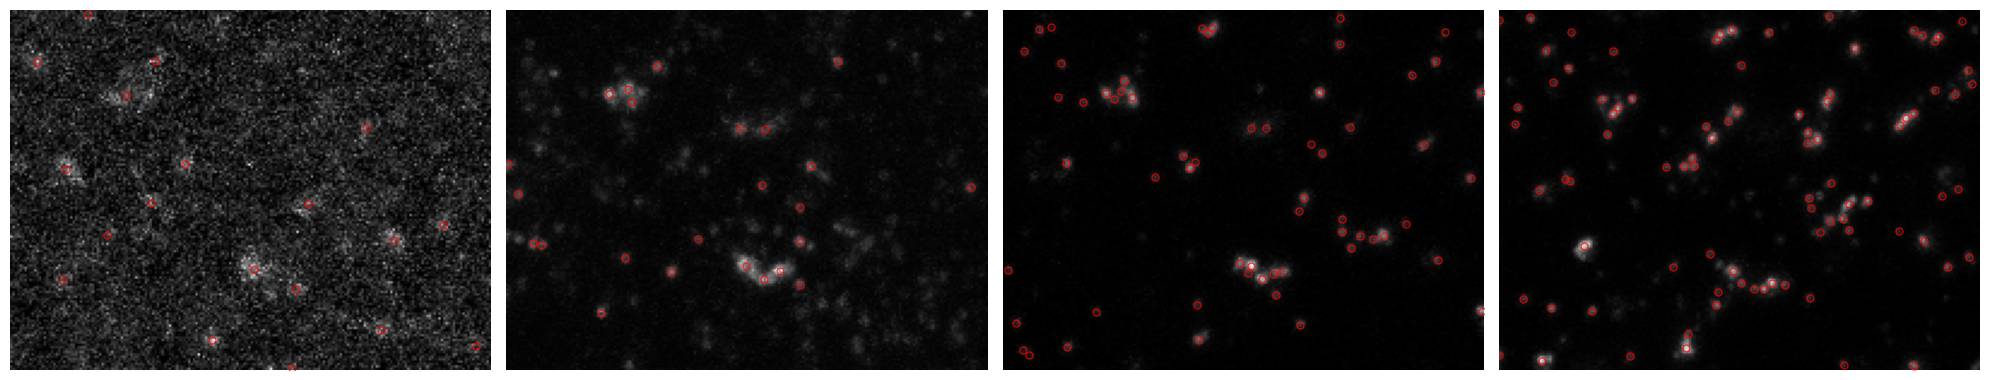

In [25]:
from prrt_clustering import detect_puncta,plot_data,plot_points
import matplotlib.pyplot as plt
import numpy as np

tmp = stabilized[0,:,:,250:400,800:1000]

points = detect_puncta(tmp, scale_um=[0.5,0.2,0.1,0.1], specificity=[3,8,6,6])

fig = plt.figure(figsize=(20,20))
fig, axes = plot_data(tmp,split=True,fig=fig)
plot_points(points, ms=10, split=True, axes=axes)


(<Figure size 2000x2000 with 4 Axes>,
 array([<Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object))

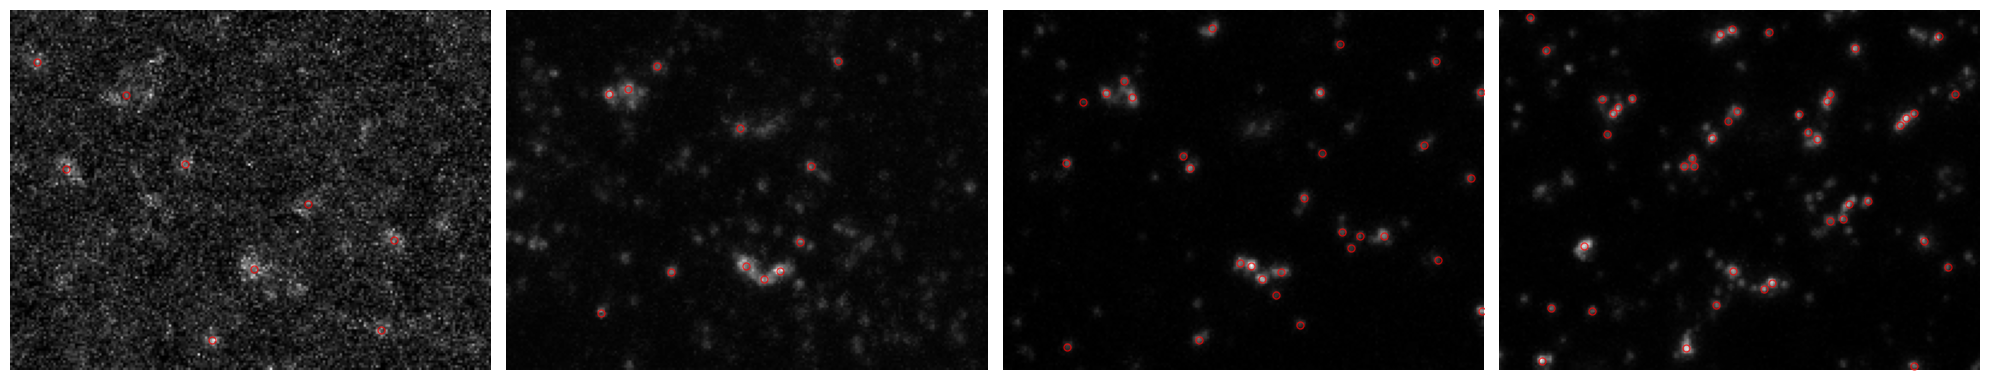

In [34]:
import pandas as pd
spoints = pd.concat([pts[pts["intensity"]>(pts["intensity"].median())]for _,pts in points.groupby("C")])
fig = plt.figure(figsize=(20,20))
fig, axes = plot_data(tmp,split=True,fig=fig)
plot_points(spoints, ms=10, split=True, axes=axes)

In [ ]:
import napari
v = napari.Viewer(ndisplay=3)
# v.add_image(image.data, channel_axis=1)
vx = np.array([(tmp[a][1].values - tmp[a][0].values) for a in ["Z", "Y", "X"]])
o = np.array([tmp[a][0].values for a in ["Z", "Y", "X"]])
v.add_image(tmp,scale=vx,translate=o, channel_axis=0)
for n,pts in points.groupby("C"):
    v.add_points(pts[["Z","Y","X"]], size=0.5, name=n)

# Identify clusters

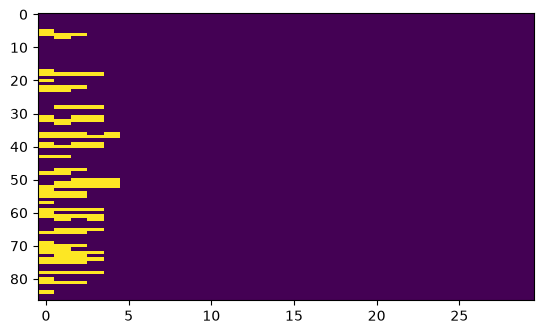

In [82]:
from prrt_clustering.clustering import BesagFeature

X = np.asarray(points[points["index"]==3][["Z","Y","X","intensity"]])
bf = BesagFeature(max_radius=10,num_radius=30)
bf.fit(X)
y = bf.transform(X)
# y = (y-y.mean(axis=0))/y.std(axis=0)
# y = y > 3
plt.imshow(y>1,aspect=.2,interpolation="nearest");

(<Figure size 2000x2000 with 1 Axes>, [<Axes: >, <Axes: >, <Axes: >, <Axes: >])

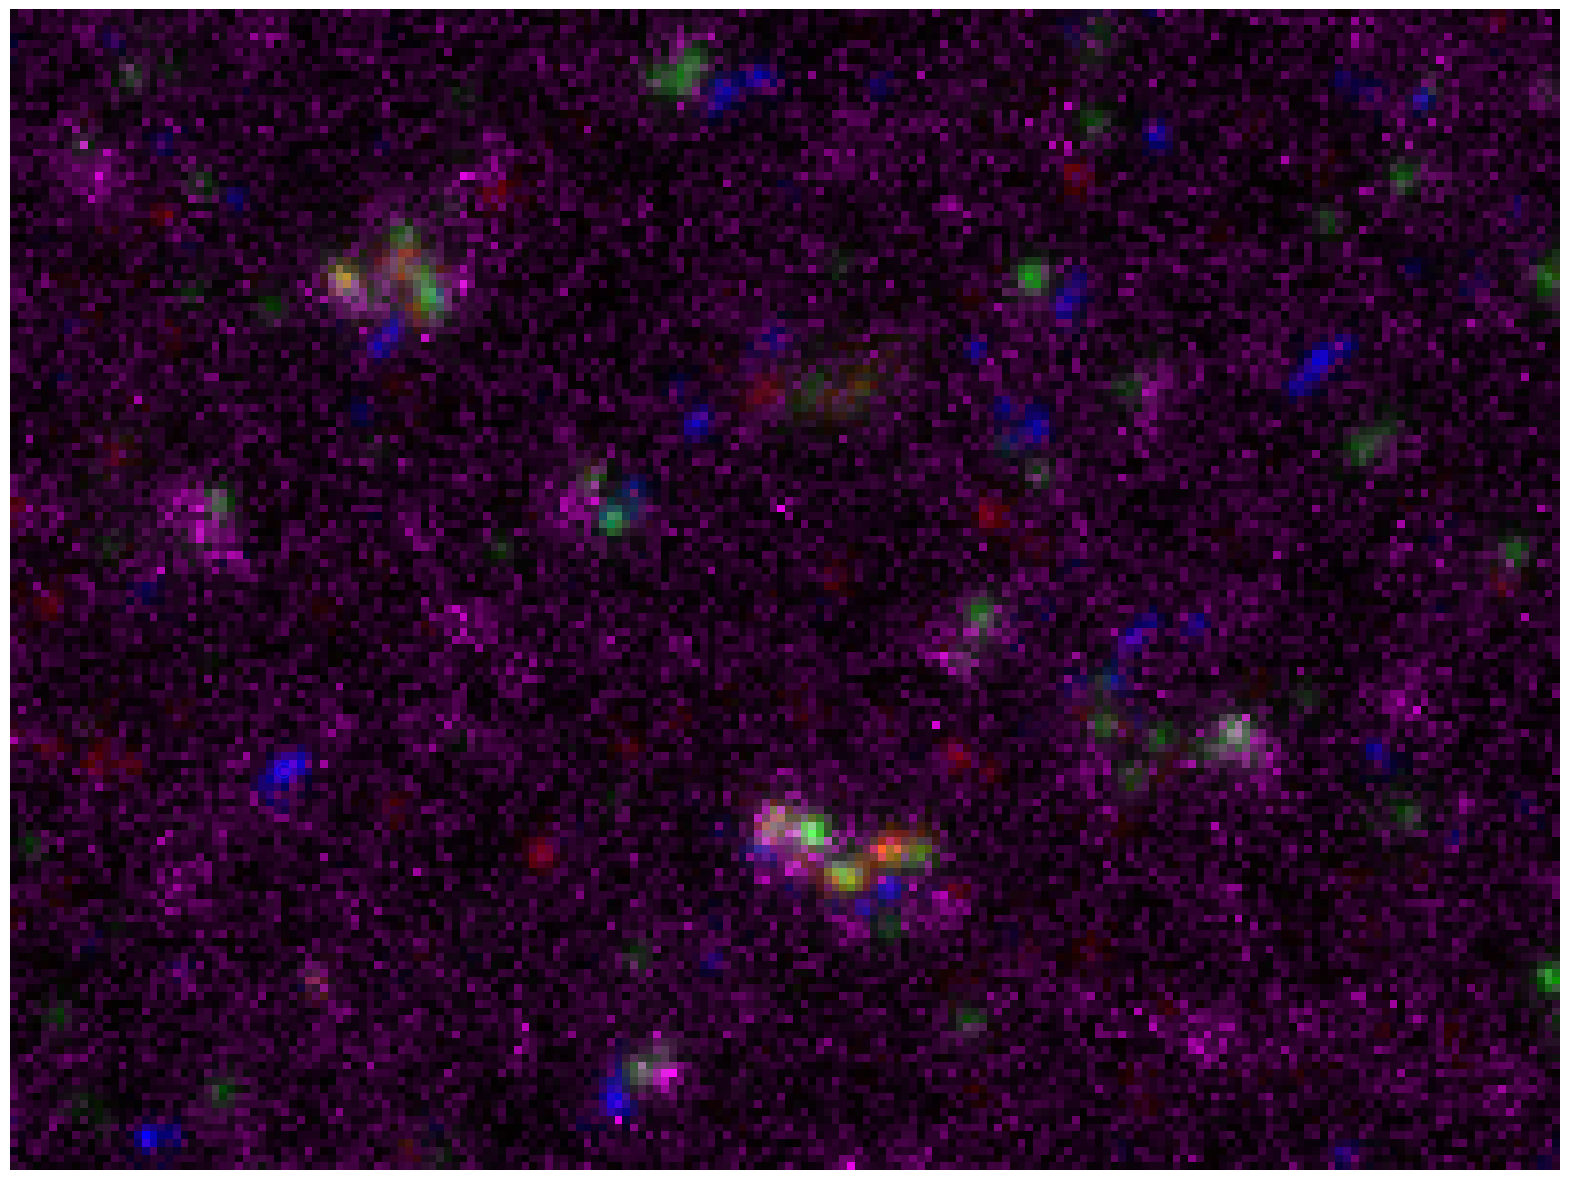

In [69]:
fig = plt.figure(figsize=(20,20))
fig, axes = plot_data(tmp,split=False,fig=fig)
# plot_points(points, ms=1, split=False, axes=axes)
plot_points(points[points["index"]==3][np.max(y[:,0:],axis=1)>2], ms=20, split=False, axes=axes)

In [ ]:
fig = plt.figure(figsize=(20,20))
fig, axes = plot_data(tmp,split=False,fig=fig)
plot_points(points[points["intensity"]>600], ms=10, split=False, axes=axes)

## 3. Clustering
Cluster points to identify potential synapses.

(<Figure size 1000x1000 with 4 Axes>,
 array([<Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object))

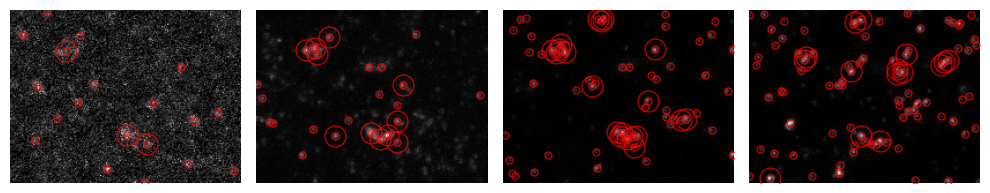

In [139]:
from prrt_clustering import clean_points_besag

clean = clean_points_besag(spoints,2,10,1.5)
clean = clean[clean["noise"]==False]  # noqa: E712
fig = plt.figure(figsize=(10,10))
fig,axes = plot_data(tmp,split=True,fig=fig)
plot_points(spoints,ms=10,split=True,axes=axes)
plot_points(clean,ms=30,split=True,axes=axes)

(<Figure size 1000x1000 with 4 Axes>,
 array([<Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object))

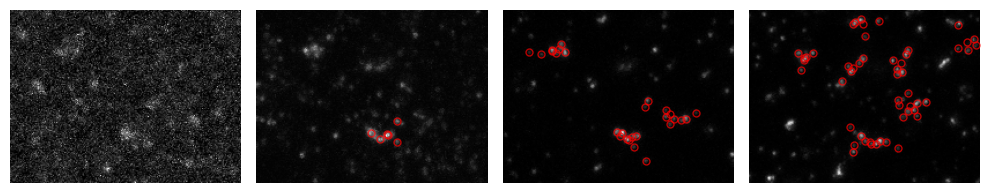

In [146]:
from prrt_clustering import cluster
spoints,clusters = cluster(points, 2, 5)
fig = plt.figure(figsize=(10,10))
fig,axes = plot_data(tmp, split=True,fig=fig)
plot_points(clusters,ms=10,split=True,axes=axes)
plot_points(spoints[spoints["noise"]==0],ms=10,split=True,axes=axes)


In [152]:
clusters

,C,cluster,Z,Y,X,intensity,area,index
0,AF488-T4,0,0.838262,33.049077,93.150845,811.444444,23.888889,3.0
1,AF488-T4,1,0.582233,27.512048,98.009546,435.600000,17.000000,3.0
2,AF488-T4,2,1.322067,36.102158,89.693545,1073.800000,24.600000,3.0
3,AF488-T4,3,1.383561,28.939333,84.118689,1222.800000,28.800000,3.0
4,AF488-T4,4,2.023836,29.362191,92.340336,1455.000000,29.666667,3.0
5,AF488-T4,5,2.350882,26.050952,89.089189,1384.400000,32.800000,3.0
6,AF488-T4,6,2.503282,29.771040,88.255137,1319.000000,30.400000,3.0
7,AF555-T3,0,1.248155,33.720492,93.688877,780.666667,39.666667,2.0
8,AF555-T3,1,1.199633,35.928949,90.203390,1573.875000,54.375000,2.0
9,AF555-T3,2,1.224866,28.278515,83.598554,1169.428571,47.571429,2.0


In [ ]:
from prrt_clustering.clustering import pair_cluster

pairs = pair_cluster(clusters, "AF555-T3", "AF488-T4", 1)
# for p in pairs.iloc:
    

C1    0
C2    0
Name: 0, dtype: int64
C1    1
C2    2
Name: 1, dtype: int64
C1    2
C2    3
Name: 2, dtype: int64


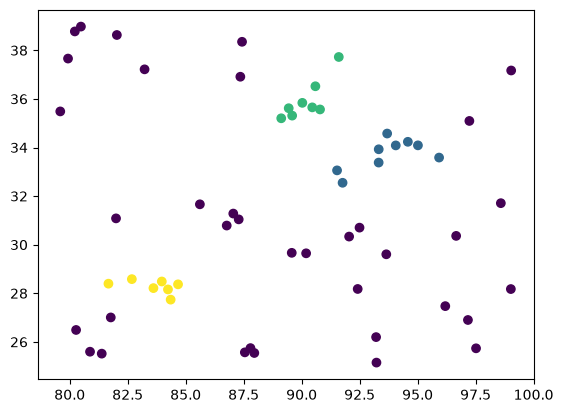

In [151]:
plt.scatter(spoints[spoints["index"]==2]["X"],spoints[spoints["index"]==2]["Y"],c=spoints[spoints["index"]==2]["cluster"])

In [147]:
clusters

,C,cluster,Z,Y,X,intensity,area,index
0,AF488-T4,0,0.838262,33.049077,93.150845,811.444444,23.888889,3.0
1,AF488-T4,1,0.582233,27.512048,98.009546,435.600000,17.000000,3.0
2,AF488-T4,2,1.322067,36.102158,89.693545,1073.800000,24.600000,3.0
3,AF488-T4,3,1.383561,28.939333,84.118689,1222.800000,28.800000,3.0
4,AF488-T4,4,2.023836,29.362191,92.340336,1455.000000,29.666667,3.0
5,AF488-T4,5,2.350882,26.050952,89.089189,1384.400000,32.800000,3.0
6,AF488-T4,6,2.503282,29.771040,88.255137,1319.000000,30.400000,3.0
7,AF555-T3,0,1.248155,33.720492,93.688877,780.666667,39.666667,2.0
8,AF555-T3,1,1.199633,35.928949,90.203390,1573.875000,54.375000,2.0
9,AF555-T3,2,1.224866,28.278515,83.598554,1169.428571,47.571429,2.0
